# Bước 4 · Game Balance & Difficulty Analysis (Phân tích cân bằng độ khó)

**Mục tiêu:** giải thích *TẠI SAO* người chơi rời bỏ ở các level đã tìm thấy ở Bước 3, bằng cách kết hợp **Win Rate – Lose Count – Play Time**.

**Cấu trúc notebook**

| Mục | Nội dung |
|---|---|
| 0 | Nạp dữ liệu & tính chỉ số phái sinh (khớp định nghĩa ở Phần 2–3 của báo cáo) |
| 4.1 | Win Rate & Lose Count: tìm Difficulty Spike, "cái bẫy ức chế" |
| 4.2 | Play Time: ván thắng vs ván thua (Kịch bản 1 / Kịch bản 2) |
| 4.3 | Phân loại level bất thường (Typology) |
| 4.4 | Liên kết với tỷ lệ rời bỏ (Churn) của Bước 3 |
| 4.5 | Câu insight tự động + khối kết quả để **copy gửi lại** |

> **Cách dùng:** chạy lần lượt từ trên xuống (`Runtime ▸ Run all` trên Colab, hoặc `Run All` trên Jupyter). Cuối notebook có khối **"KẾT QUẢ BƯỚC 4"** — hãy copy toàn bộ phần in ra và gửi lại để viết tiếp báo cáo.

## 0. Thiết lập & nạp dữ liệu

In [1]:
import os, warnings
from IPython.display import display
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 50)
pd.set_option("display.max_rows", 100)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .25,
                     "axes.spines.top": False, "axes.spines.right": False})

# ====== THAM SỐ (có thể chỉnh) ======
CSV_PATH     = "DA_Test_02_game_analytics.csv"
SPIKE_MULT   = 3      # Spike: Lose_Count >= 3 x trung vị (giữ nguyên định nghĩa ở Phần 2)
LONG_LOSE_S  = 80     # mốc tham khảo theo đề bài: ván thua > 80 giây
OUT_DIR      = "step4_outputs"
os.makedirs(OUT_DIR, exist_ok=True)

# Nếu chạy trên Google Colab mà chưa có file -> hiện hộp thoại upload
if not os.path.exists(CSV_PATH):
    try:
        from google.colab import files
        up = files.upload()
        CSV_PATH = list(up.keys())[0]
    except ImportError:
        raise FileNotFoundError(f"Không thấy {CSV_PATH}. Đặt file cùng thư mục với notebook.")

raw = pd.read_csv(CSV_PATH)
df = raw.rename(columns={"Drop_off_by_level": "Users", "Win_Play_time_s": "Win_Time",
                         "Win_count": "Win_Count", "Lose_Play_time_s": "Lose_Time",
                         "Lose_count": "Lose_Count"}).copy()
print("Kích thước:", df.shape)
df.head()

Kích thước: (51, 6)


,Level,Users,Win_Time,Win_Count,Lose_Time,Lose_Count
0,0,78397,NaN,NaN,NaN,NaN
1,1,63683,15.65,65170.0,NaN,NaN
2,2,61516,15.30,63584.0,45.68,404.0
3,3,59738,33.59,60562.0,76.67,564.0
4,4,53534,46.36,55594.0,66.56,798.0


### 0.1 Chỉ số phái sinh
Dùng **đúng định nghĩa ở mục 2.5 của báo cáo** để số liệu khớp với Phần 1–3:

- `Churn` = (Users_L − Users_L+1) / Users_L × 100 
- `Win_Rate` = Win / (Win + Lose) × 100 — tính từ L2 (L1 chưa có dữ liệu thua)
- `Attempts_per_User` = (Win + Lose) / Users — L1 coi Lose = 0
- `Spike` = `Lose_Count` ≥ 3 × trung vị (L2–L50)
- Bổ sung cho Bước 4: `Lose_vs_Neighbors` (lượt thua gấp mấy lần level liền kề), `Time_Gap` (thua − thắng), `Time_Wasted_h` (tổng giờ người chơi "đổ" vào các ván thua), `WR_Jump` (độ gãy của tỷ lệ thắng so với level trước)

In [2]:
d = df.copy()

# --- Phễu & churn ---
d["Churn"] = (d["Users"] - d["Users"].shift(-1)) / d["Users"] * 100

# --- Win / Lose ---
d["Lose_Count_f"]   = d["Lose_Count"].fillna(0)           # L1: coi bằng 0 khi tính lượt chơi/người
d["Attempts"]       = d["Win_Count"] + d["Lose_Count_f"]
d["Attempts_per_User"] = d["Attempts"] / d["Users"]
d["Win_Rate"]       = np.where(d["Lose_Count"].notna(), d["Win_Count"] / (d["Win_Count"] + d["Lose_Count"]) * 100, np.nan)
d["Lose_Rate"]      = 100 - d["Win_Rate"]

# --- Spike ---
play = d[d["Level"] >= 2]                                  # L2-L50: có đủ dữ liệu thắng & thua
LOSE_MED   = play["Lose_Count"].median()
SPIKE_THR  = SPIKE_MULT * LOSE_MED
d["Spike"] = d["Lose_Count"] >= SPIKE_THR

# --- So với level liền kề ---
nb = pd.concat([d["Lose_Count"].shift(1), d["Lose_Count"].shift(-1)], axis=1).mean(axis=1)   # TB của level trước & sau
d["Lose_vs_Neighbors"] = d["Lose_Count"] / nb
d["WR_Jump"]  = d["Win_Rate"].diff()                        # âm = tỷ lệ thắng tụt so với level trước (pp)
d["Lose_Rate_Jump"] = d["Lose_Rate"].diff()

# --- Thời gian ---
d["Time_Gap"]        = d["Lose_Time"] - d["Win_Time"]       # >0: thua lâu hơn thắng
d["Lose_Win_Ratio"]  = d["Lose_Time"] / d["Win_Time"]
d["Lose_Hours"]      = d["Lose_Count"] * d["Lose_Time"] / 3600     # tổng giờ chơi dồn vào ván thua
d["Win_Hours"]       = d["Win_Count"]  * d["Win_Time"]  / 3600
d["Lose_Time_Share"] = d["Lose_Hours"] / (d["Lose_Hours"] + d["Win_Hours"]) * 100

# --- Ngưỡng tham chiếu (tính trên L2-L50 / L1-L49) ---
play = d[d["Level"] >= 2]
WR_MEAN, WR_STD = play["Win_Rate"].mean(), play["Win_Rate"].std()
WR_LOW      = WR_MEAN - WR_STD                              # "tỷ lệ thắng thấp" (tương đối)
LT_MED      = play["Lose_Time"].median()
LT_P25, LT_P75 = play["Lose_Time"].quantile([.25, .75])
WT_P25, WT_P75 = play["Win_Time"].quantile([.25, .75])
LC_P25      = play["Lose_Count"].quantile(.25)
ch          = d[(d["Level"] >= 1) & (d["Level"] <= 49)]["Churn"]
CHURN_MEAN, CHURN_STD = ch.mean(), ch.std()
CHURN_THR   = CHURN_MEAN + CHURN_STD                        # ngưỡng "rời bỏ cao" (khớp mục 3.1 = 6,7%)

ref = pd.Series({
    "Trung vị Lose_Count (L2-50)": LOSE_MED,
    f"Ngưỡng Spike ({SPIKE_MULT}x trung vị)": SPIKE_THR,
    "Win_Rate TB (%)": WR_MEAN, "Win_Rate độ lệch chuẩn": WR_STD,
    "Ngưỡng Win_Rate thấp = TB - 1 SD (%)": WR_LOW,
    "Lose_Time trung vị (s)": LT_MED, "Lose_Time P25 / P75 (s)": f"{LT_P25:.1f} / {LT_P75:.1f}",
    "Win_Time P25 / P75 (s)": f"{WT_P25:.1f} / {WT_P75:.1f}",
    "Churn TB L1-49 (%)": CHURN_MEAN, "Ngưỡng Churn cao = TB + 1 SD (%)": CHURN_THR,
})
print("Số level Spike:", int(d["Spike"].sum()), "→", d.loc[d["Spike"], "Level"].tolist())
ref.to_frame("Giá trị")

Số level Spike: 8 → [22, 28, 29, 32, 34, 37, 42, 45]


,Giá trị
Trung vị Lose_Count (L2-50),1794.0
Ngưỡng Spike (3x trung vị),5382.0
Win_Rate TB (%),90.327866
Win_Rate độ lệch chuẩn,9.212351
Ngưỡng Win_Rate thấp = TB - 1 SD (%),81.115515
Lose_Time trung vị (s),64.53
Lose_Time P25 / P75 (s),52.9 / 71.9
Win_Time P25 / P75 (s),50.2 / 86.5
Churn TB L1-49 (%),4.082878
Ngưỡng Churn cao = TB + 1 SD (%),6.747551


> **Lưu ý về ngưỡng.** Đề bài gợi ý "Win Rate dưới 50%" và "ván thua > 80–100 giây", nhưng dữ liệu thực tế cho thấy **không level nào có Win Rate < 50%** (thấp nhất ≈ 68,7%) và **ván thua dài nhất chỉ ≈ 88 giây**. Vì vậy notebook dùng **ngưỡng tương đối** (so với mặt bằng chung của game: TB − 1 SD, phân vị P25/P75) làm tiêu chí chính; mốc 80 giây vẫn được hiển thị để đối chiếu.

## 4.1 Win Rate & Lose Count — tìm Difficulty Spike và "cái bẫy ức chế"

Hai câu hỏi: (1) Lượt thua có **vọt đột ngột** so với level liền kề không? (2) Tỷ lệ thắng ở đó có **thấp bất thường** so với mặt bằng chung không?

In [3]:
cols = ["Level", "Lose_Count", "Win_Rate", "Lose_vs_Neighbors", "WR_Jump", "Attempts_per_User", "Churn"]
spk = d.loc[d["Spike"], cols].sort_values("Lose_Count", ascending=False).copy()
spk["Win_Rate_thấp?"] = spk["Win_Rate"] < WR_LOW
spk["Lose_Count_gấp_trung_vị"] = spk["Lose_Count"] / LOSE_MED
print(f"8 level Spike  |  ngưỡng Lose_Count ≥ {SPIKE_THR:,.0f}  |  ngưỡng Win_Rate thấp < {WR_LOW:.1f}%")
spk.round(2).reset_index(drop=True)

8 level Spike  |  ngưỡng Lose_Count ≥ 5,382  |  ngưỡng Win_Rate thấp < 81.1%


,Level,Lose_Count,Win_Rate,Lose_vs_Neighbors,WR_Jump,Attempts_per_User,Churn,Win_Rate_thấp?,Lose_Count_gấp_trung_vị
0,22,8090.0,73.87,4.07,-25.81,1.70,6.06,True,4.51
1,34,7790.0,69.44,2.89,-25.01,2.09,5.25,True,4.34
2,29,6786.0,74.53,2.27,-3.92,1.87,5.42,True,3.78
3,42,6773.0,69.61,22.13,-30.04,2.25,5.29,True,3.78
4,45,6708.0,68.67,4.47,-26.54,2.36,4.29,True,3.74
5,28,5617.0,78.45,1.30,-13.50,1.75,3.89,True,3.13
6,32,5610.0,77.03,7.98,-21.43,1.85,6.08,True,3.13
7,37,5598.0,75.01,1.67,-6.92,2.05,3.70,True,3.12


In [4]:
# Tóm tắt: nhóm Spike vs nhóm còn lại (L2-L50)
g = d[d["Level"] >= 2].groupby("Spike").agg(
    So_level=("Level", "count"),
    Win_Rate_TB=("Win_Rate", "mean"),
    Lose_Count_TB=("Lose_Count", "mean"),
    Attempts_per_User=("Attempts_per_User", "mean"),
    Churn_TB=("Churn", "mean"),
    Tong_Lose=("Lose_Count", "sum"))
g["% tổng lượt thua"] = g["Tong_Lose"] / g["Tong_Lose"].sum() * 100
g.index = g.index.map({True: "Spike", False: "Không Spike"})
g.round(2)

,So_level,Win_Rate_TB,Lose_Count_TB,Attempts_per_User,Churn_TB,Tong_Lose,% tổng lượt thua
Spike,,,,,,,
Không Spike,41,93.64,1630.05,1.46,3.92,66832.0,55.78
Spike,8,73.33,6621.50,1.99,5.00,52972.0,44.22


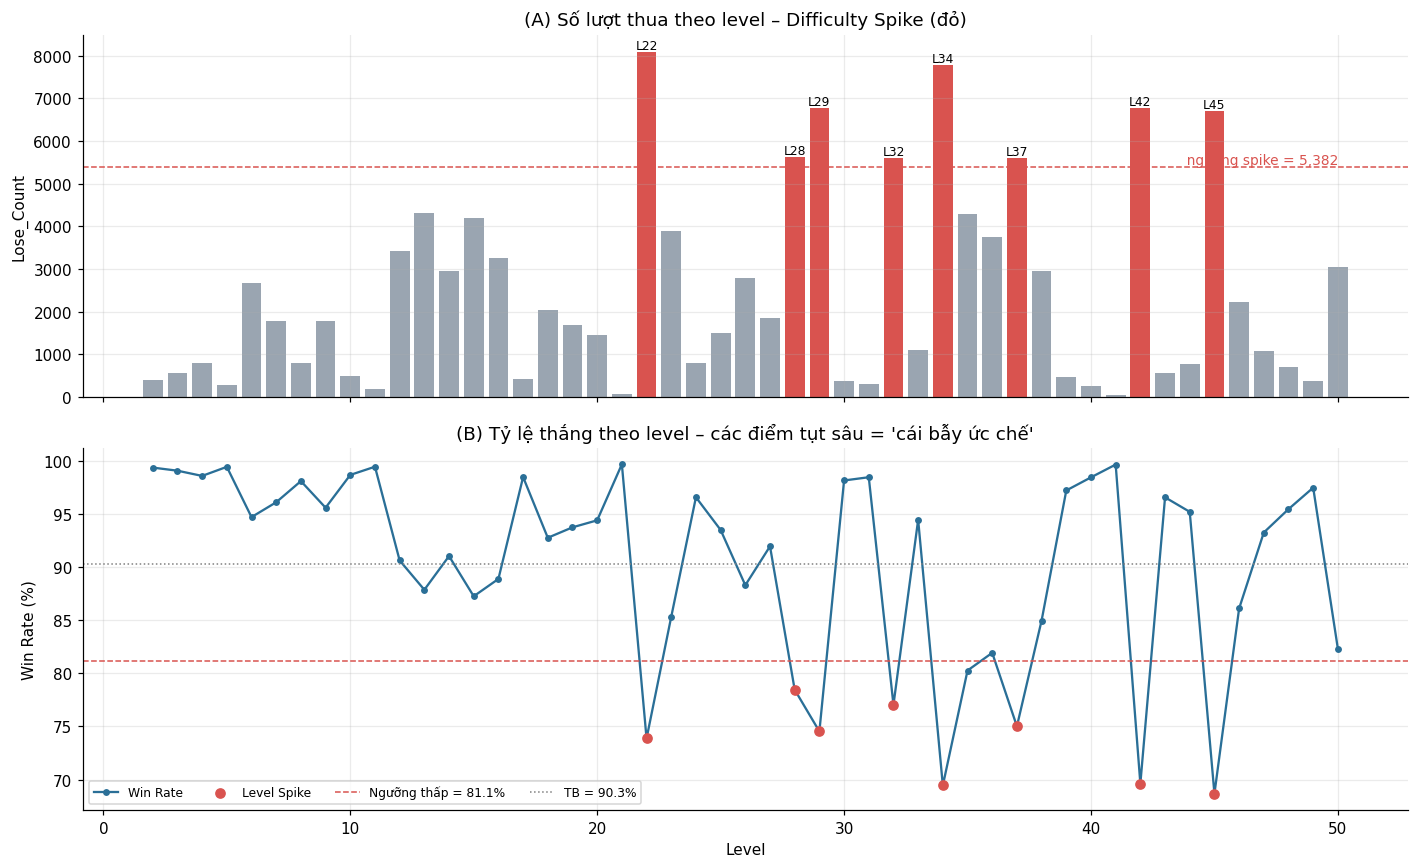

In [5]:
# Đường cong độ khó: có tăng tịnh tiến hay gãy khúc?
p = d[d["Level"] >= 2].copy()
p["Lose_Rate_roll5"] = p["Lose_Rate"].rolling(5, center=True, min_periods=3).median()

fig, ax = plt.subplots(2, 1, figsize=(13, 8), sharex=True)
colors = np.where(p["Spike"], "#d9534f", "#9aa5b1")
ax[0].bar(p["Level"], p["Lose_Count"], color=colors)
ax[0].axhline(SPIKE_THR, color="#d9534f", ls="--", lw=1)
ax[0].text(p["Level"].max(), SPIKE_THR, f"  ngưỡng spike = {SPIKE_THR:,.0f}", va="bottom", ha="right", color="#d9534f", fontsize=9)
for _, r in p[p["Spike"]].iterrows():
    ax[0].annotate(f"L{int(r.Level)}", (r.Level, r.Lose_Count), ha="center", va="bottom", fontsize=8)
ax[0].set_ylabel("Lose_Count"); ax[0].set_title("(A) Số lượt thua theo level – Difficulty Spike (đỏ)")

ax[1].plot(p["Level"], p["Win_Rate"], marker="o", ms=3.5, color="#2a6f97", label="Win Rate")
ax[1].scatter(p.loc[p["Spike"], "Level"], p.loc[p["Spike"], "Win_Rate"], color="#d9534f", zorder=3, label="Level Spike")
ax[1].axhline(WR_LOW, color="#d9534f", ls="--", lw=1, label=f"Ngưỡng thấp = {WR_LOW:.1f}%")
ax[1].axhline(WR_MEAN, color="gray", ls=":", lw=1, label=f"TB = {WR_MEAN:.1f}%")
ax[1].set_ylabel("Win Rate (%)"); ax[1].set_xlabel("Level")
ax[1].set_title("(B) Tỷ lệ thắng theo level – các điểm tụt sâu = 'cái bẫy ức chế'"); ax[1].legend(ncol=4, fontsize=8)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/fig1_winrate_losecount.png", bbox_inches="tight"); plt.show()

In [6]:
# Độ "gãy khúc" của đường cong: level nào tỷ lệ thắng tụt mạnh nhất so với level ngay trước?
whip = d[d["Level"] >= 3][["Level", "Win_Rate", "WR_Jump", "Lose_Count", "Spike"]].sort_values("WR_Jump").head(10)
print("Top 10 level có Win Rate tụt mạnh nhất so với level liền trước (pp = điểm phần trăm):")
whip.round(2).reset_index(drop=True)

Top 10 level có Win Rate tụt mạnh nhất so với level liền trước (pp = điểm phần trăm):


,Level,Win_Rate,WR_Jump,Lose_Count,Spike
0,42,69.61,-30.04,6773.0,True
1,45,68.67,-26.54,6708.0,True
2,22,73.87,-25.81,8090.0,True
3,34,69.44,-25.01,7790.0,True
4,32,77.03,-21.43,5610.0,True
5,50,82.31,-15.17,3059.0,False
6,28,78.45,-13.50,5617.0,True
7,12,90.63,-8.83,3412.0,False
8,37,75.01,-6.92,5598.0,True
9,18,92.76,-5.72,2041.0,False


## 4.2 Play Time — ván thắng vs ván thua

- **Kịch bản 1 – Ván thua quá dài:** người chơi tốn nhiều thời gian nhưng vẫn thua → độc hại nhất cho trải nghiệm.
- **Kịch bản 2 – Ván thua quá ngắn (fail nhanh):** chết ngay từ đầu ván → ít ức chế hơn nhưng lặp lại nhiều cũng gây chán.

Phân loại theo phân vị của chính game: ván thua **dài** nếu `Lose_Time ≥ P75`, **ngắn** nếu `Lose_Time ≤ P25`.

In [7]:
d["Lose_Long"]  = d["Lose_Time"] >= LT_P75
d["Lose_Short"] = d["Lose_Time"] <= LT_P25
d["Lose_ge_80s"] = d["Lose_Time"] >= LONG_LOSE_S
d["Kich_ban"] = np.select([d["Lose_Long"], d["Lose_Short"]], ["KB1 – Thua dài", "KB2 – Thua ngắn"], default="Trung bình")
d.loc[d["Level"] < 2, "Kich_ban"] = "n/a"

pl = d[d["Level"] >= 2]
print(f"Ván thua ≥ {LONG_LOSE_S}s (mốc theo đề bài):", pl.loc[pl["Lose_ge_80s"], "Level"].tolist())
print(f"Ván thua ≥ P75 = {LT_P75:.1f}s (KB1):", pl.loc[pl["Lose_Long"], "Level"].tolist())
print(f"Ván thua ≤ P25 = {LT_P25:.1f}s (KB2):", pl.loc[pl["Lose_Short"], "Level"].tolist())

# Chéo với Spike
ct = pd.crosstab(pl["Kich_ban"], pl["Spike"].map({True: "Spike", False: "Không Spike"}), margins=True)
display(ct)

Ván thua ≥ 80s (mốc theo đề bài): [9, 13, 18, 20, 25, 32, 42]
Ván thua ≥ P75 = 71.9s (KB1): [3, 9, 13, 15, 18, 19, 20, 25, 29, 32, 34, 35, 42]
Ván thua ≤ P25 = 52.9s (KB2): [2, 11, 16, 17, 21, 24, 27, 30, 31, 33, 40, 41, 48]


Spike,Không Spike,Spike,All
Kich_ban,,,
KB1 – Thua dài,9,4,13
KB2 – Thua ngắn,13,0,13
Trung bình,19,4,23
All,41,8,49


In [8]:
# Thời gian trung bình & tổng giờ "đổ vào ván thua" theo nhóm
t = pl.groupby(pl["Spike"].map({True: "Spike", False: "Không Spike"})).agg(
    Win_Time_TB=("Win_Time", "mean"), Lose_Time_TB=("Lose_Time", "mean"),
    Time_Gap_TB=("Time_Gap", "mean"), Lose_Hours_TB=("Lose_Hours", "mean"),
    Lose_Time_Share_TB=("Lose_Time_Share", "mean"))
print(f"Thời gian ván thắng ở Spike dài gấp {t.loc['Spike','Win_Time_TB']/t.loc['Không Spike','Win_Time_TB']:.2f}x level thường; "
      f"ván thua dài gấp {t.loc['Spike','Lose_Time_TB']/t.loc['Không Spike','Lose_Time_TB']:.2f}x.")
t.round(2)

Thời gian ván thắng ở Spike dài gấp 1.54x level thường; ván thua dài gấp 1.22x.


,Win_Time_TB,Lose_Time_TB,Time_Gap_TB,Lose_Hours_TB,Lose_Time_Share_TB
Spike,,,,,
Không Spike,64.36,60.96,-3.39,30.00,5.55
Spike,99.20,74.34,-24.86,137.01,21.52


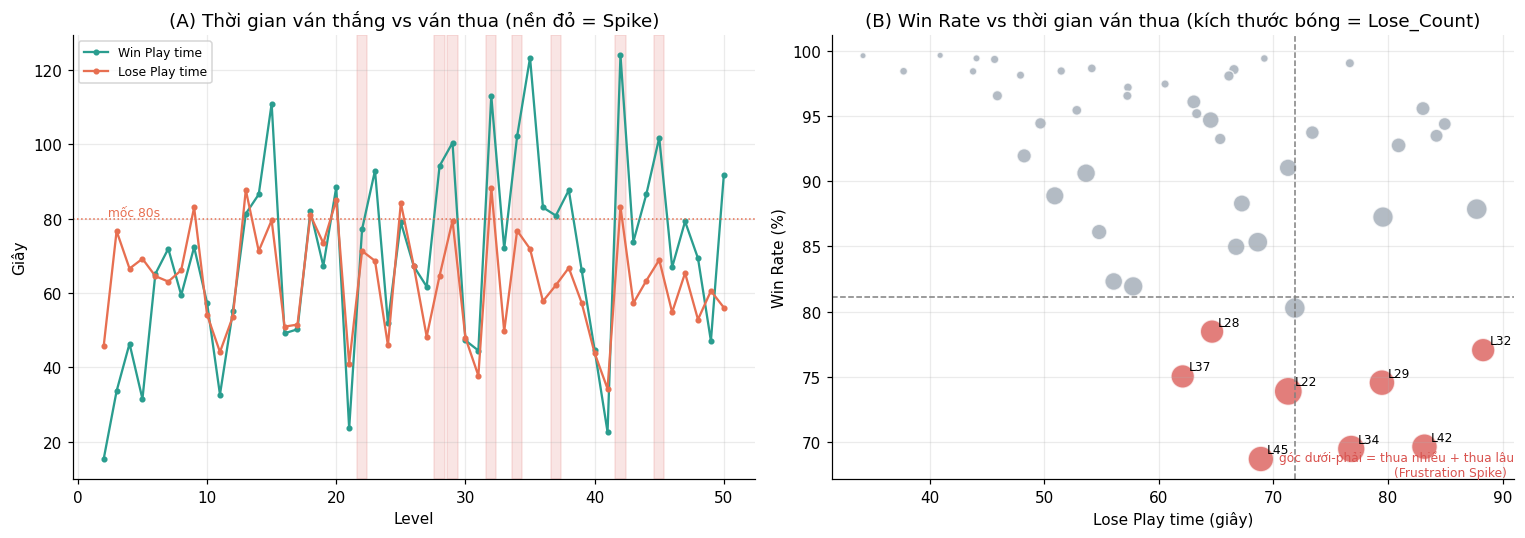

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# (A) Thời gian thắng vs thua theo level
a = ax[0]
a.plot(pl["Level"], pl["Win_Time"],  color="#2a9d8f", marker="o", ms=3, label="Win Play time")
a.plot(pl["Level"], pl["Lose_Time"], color="#e76f51", marker="o", ms=3, label="Lose Play time")
a.axhline(LONG_LOSE_S, color="#e76f51", ls=":", lw=1)
a.text(pl["Level"].min(), LONG_LOSE_S, f" mốc {LONG_LOSE_S}s", color="#e76f51", va="bottom", fontsize=8)
for lv in pl.loc[pl["Spike"], "Level"]:
    a.axvspan(lv-.4, lv+.4, color="#d9534f", alpha=.15)
a.set_xlabel("Level"); a.set_ylabel("Giây"); a.set_title("(A) Thời gian ván thắng vs ván thua (nền đỏ = Spike)"); a.legend(fontsize=8)

# (B) Win Rate vs Lose Time, kích thước = Lose_Count
b = ax[1]
sc = b.scatter(pl["Lose_Time"], pl["Win_Rate"], s=pl["Lose_Count"]/25+15,
               c=np.where(pl["Spike"], "#d9534f", "#9aa5b1"), alpha=.75, edgecolor="white")
b.axvline(LT_P75, color="gray", ls="--", lw=1); b.axhline(WR_LOW, color="gray", ls="--", lw=1)
for _, r in pl[pl["Spike"]].iterrows():
    b.annotate(f"L{int(r.Level)}", (r.Lose_Time, r.Win_Rate), xytext=(4, 4), textcoords="offset points", fontsize=8)
b.text(b.get_xlim()[1], b.get_ylim()[0], "góc dưới-phải = thua nhiều + thua lâu\n(Frustration Spike)  ", ha="right", va="bottom", fontsize=8, color="#d9534f")
b.set_xlabel("Lose Play time (giây)"); b.set_ylabel("Win Rate (%)")
b.set_title("(B) Win Rate vs thời gian ván thua (kích thước bóng = Lose_Count)")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/fig2_playtime.png", bbox_inches="tight"); plt.show()

In [10]:
# Khoảng cách thời gian thua - thắng theo 2 nửa game (khớp mục 2.6 / Biểu đồ 3)
d["Nua_game"] = np.where(d["Level"].between(2, 25), "L2-25", np.where(d["Level"] >= 26, "L26-50", "n/a"))
h = d[d["Nua_game"] != "n/a"].groupby("Nua_game").agg(Win_Time=("Win_Time", "mean"), Lose_Time=("Lose_Time", "mean"),
                                                    Time_Gap=("Time_Gap", "mean"),
                                                    So_level_thua_dai_hon_thang=("Time_Gap", lambda s: int((s > 0).sum())),
                                                    So_level=("Level", "count"))
h.round(2)

,Win_Time,Lose_Time,Time_Gap,So_level_thua_dai_hon_thang,So_level
Nua_game,,,,,
L2-25,61.72,65.75,4.04,13,24
L26-50,78.04,60.65,-17.40,4,25


## 4.3 Typology — phân loại các level bất thường

Quy tắc (ưu tiên từ trên xuống), dùng các ngưỡng đã tính ở mục 0:

| Nhóm | Điều kiện |
|---|---|
| **G1 – Frustration Spike** | `Spike` **và** `Lose_Time ≥ trung vị` (thua nhiều + Win Rate thấp + ván thua dài) |
| **G3 – Short-lose Spike** | `Spike` nhưng `Lose_Time < trung vị` (thua nhiều nhưng ván thua tương đối ngắn, gần Kịch bản 2) |
| **G2 – Grinding / Tedious** | Không Spike, `Win_Time ≥ P75` **và** `Lose_Time ≥ P75` (dài ở cả hai loại ván, lượng thua không quá cao) |
| **G4 – Early Friction** | Không Spike, `Level ≤ 15`, `Churn ≥ ngưỡng cao` (rời bỏ nhiều dù không quá khó) |
| **G5 – Breather / Easy** | `Level ≥ 10`, `Lose_Count ≤ P25` **và** `Win_Time ≤ P25` (level "thở", dễ và nhanh) |
| Bình thường | Còn lại |

In [11]:
def classify(r):
    if r["Level"] < 2 or pd.isna(r["Lose_Count"]):
        return "n/a"
    if r["Spike"] and r["Lose_Time"] >= LT_MED:                       return "G1 Frustration Spike"
    if r["Spike"]:                                                    return "G3 Short-lose Spike"
    if r["Win_Time"] >= WT_P75 and r["Lose_Time"] >= LT_P75:          return "G2 Grinding/Tedious"
    if r["Level"] <= 15 and r["Churn"] >= CHURN_THR:                  return "G4 Early Friction"
    if r["Level"] >= 10 and r["Lose_Count"] <= LC_P25 and r["Win_Time"] <= WT_P25: return "G5 Breather/Easy"
    return "Bình thường"

d["Nhom"] = d.apply(classify, axis=1)

order = ["G1 Frustration Spike", "G3 Short-lose Spike", "G2 Grinding/Tedious", "G4 Early Friction", "G5 Breather/Easy", "Bình thường"]
lv_list = d[d["Nhom"].isin(order)].groupby("Nhom")["Level"].apply(lambda s: ", ".join(f"L{int(x)}" for x in s)).reindex(order)

tot_lost_users = d.loc[d["Level"].between(0, 49), "Users"].sub(d["Users"].shift(-1)).sum()
typ = d[d["Nhom"].isin(order)].groupby("Nhom").agg(
    So_level=("Level", "count"),
    Win_Rate_TB=("Win_Rate", "mean"), Lose_Count_TB=("Lose_Count", "mean"),
    Win_Time_TB=("Win_Time", "mean"), Lose_Time_TB=("Lose_Time", "mean"),
    Attempts_per_User=("Attempts_per_User", "mean"), Churn_TB=("Churn", "mean"),
    Tong_Lose=("Lose_Count", "sum")).reindex(order)
typ["Nguoi_roi_di"] = d[d["Nhom"].isin(order)].assign(L=lambda x: x["Users"] - d["Users"].shift(-1).loc[x.index]).groupby("Nhom")["L"].sum().reindex(order)
typ["% tổng lượt thua"] = typ["Tong_Lose"] / d["Lose_Count"].sum() * 100
typ.insert(0, "Các level", lv_list)
typ.round(2)

,Các level,So_level,Win_Rate_TB,Lose_Count_TB,Win_Time_TB,Lose_Time_TB,Attempts_per_User,Churn_TB,Tong_Lose,Nguoi_roi_di,% tổng lượt thua
Nhom,,,,,,,,,,,
G1 Frustration Spike,"L22, L28, L29, L32, L34, L42, L45",7,73.09,6767.71,101.82,76.09,1.98,5.18,47374.0,4812.0,39.54
G3 Short-lose Spike,L37,1,75.01,5598.00,80.82,62.09,2.05,3.70,5598.0,404.0,4.67
G2 Grinding/Tedious,"L15, L20, L35",3,87.31,3317.00,107.58,78.79,1.55,4.63,9951.0,2622.0,8.31
G4 Early Friction,"L3, L4, L5, L6, L7, L8, L9, L13",8,96.18,1628.50,57.69,72.12,1.12,8.54,13028.0,30057.0,10.87
G5 Breather/Easy,"L11, L17, L21, L30, L31, L40, L41, L49",8,98.73,258.62,39.05,45.09,1.49,1.28,2069.0,1981.0,1.73
Bình thường,"L2, L10, L12, L14, L16, L18, L19, L23, L24, L2...",22,91.74,1899.27,70.09,60.25,1.57,3.06,41784.0,13534.0,34.88


In [12]:
# Chi tiết từng level thuộc nhóm có vấn đề (G1, G2, G3, G4)
detail_cols = ["Level", "Nhom", "Lose_Count", "Win_Rate", "Win_Time", "Lose_Time", "Time_Gap",
               "Lose_vs_Neighbors", "Attempts_per_User", "Churn"]
problem = d[d["Nhom"].isin(order[:4])][detail_cols].sort_values(["Nhom", "Lose_Count"], ascending=[True, False])
problem.round(2).reset_index(drop=True)

,Level,Nhom,Lose_Count,Win_Rate,Win_Time,Lose_Time,Time_Gap,Lose_vs_Neighbors,Attempts_per_User,Churn
0,22,G1 Frustration Spike,8090.0,73.87,77.15,71.30,-5.85,4.07,1.70,6.06
1,34,G1 Frustration Spike,7790.0,69.44,102.15,76.79,-25.36,2.89,2.09,5.25
2,29,G1 Frustration Spike,6786.0,74.53,100.43,79.47,-20.96,2.27,1.87,5.42
3,42,G1 Frustration Spike,6773.0,69.61,123.96,83.18,-40.78,22.13,2.25,5.29
4,45,G1 Frustration Spike,6708.0,68.67,101.77,68.91,-32.86,4.47,2.36,4.29
5,28,G1 Frustration Spike,5617.0,78.45,94.20,64.65,-29.55,1.30,1.75,3.89
6,32,G1 Frustration Spike,5610.0,77.03,113.09,88.30,-24.79,7.98,1.85,6.08
7,35,G2 Grinding/Tedious,4296.0,80.26,123.32,71.87,-51.45,0.74,1.88,4.11
8,15,G2 Grinding/Tedious,4192.0,87.26,110.95,79.56,-31.39,1.35,1.38,6.02
9,20,G2 Grinding/Tedious,1463.0,94.40,88.47,84.95,-3.52,1.66,1.38,3.75


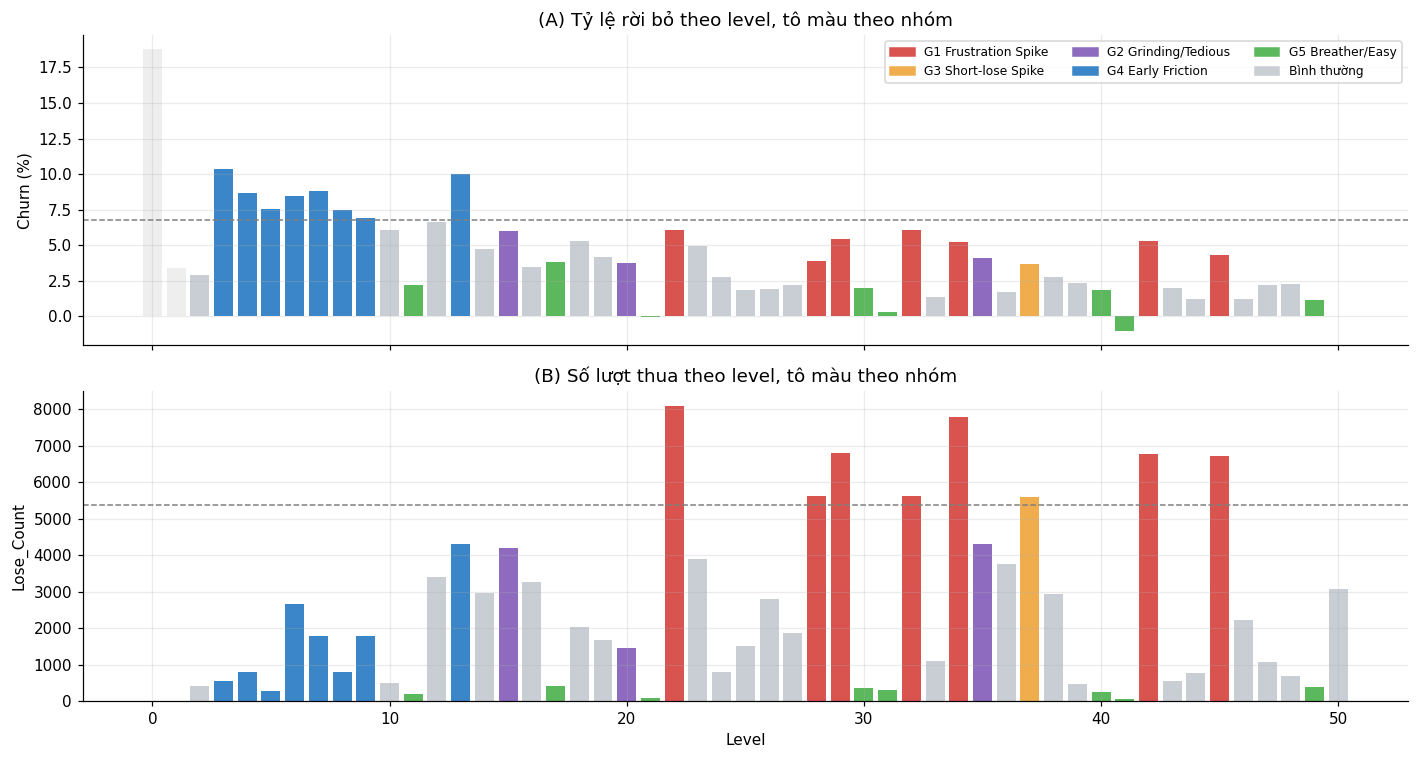

In [13]:
pal = {"G1 Frustration Spike": "#d9534f", "G3 Short-lose Spike": "#f0ad4e", "G2 Grinding/Tedious": "#8e6bbf",
       "G4 Early Friction": "#3a86c8", "G5 Breather/Easy": "#5cb85c", "Bình thường": "#c9ced4", "n/a": "#eeeeee"}
fig, ax = plt.subplots(2, 1, figsize=(13, 7), sharex=True)
ax[0].bar(d["Level"], d["Churn"].fillna(0), color=d["Nhom"].map(pal))
ax[0].axhline(CHURN_THR, color="gray", ls="--", lw=1); ax[0].set_ylabel("Churn (%)")
ax[0].set_title("(A) Tỷ lệ rời bỏ theo level, tô màu theo nhóm")
ax[1].bar(d["Level"], d["Lose_Count"].fillna(0), color=d["Nhom"].map(pal))
ax[1].axhline(SPIKE_THR, color="gray", ls="--", lw=1); ax[1].set_ylabel("Lose_Count"); ax[1].set_xlabel("Level")
ax[1].set_title("(B) Số lượt thua theo level, tô màu theo nhóm")
from matplotlib.patches import Patch
ax[0].legend(handles=[Patch(color=v, label=k) for k, v in pal.items() if k not in ("n/a",)], ncol=3, fontsize=8, loc="upper right")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/fig3_typology.png", bbox_inches="tight"); plt.show()

## 4.4 Liên kết với Churn (Bước 3) — các level mất người nhiều có "khó" không?

Trả lời trực tiếp câu hỏi của bước này: *ở các level rời bỏ cao đã tìm thấy ở Bước 3, nguyên nhân là độ khó (Win Rate thấp / thua lâu) hay là nguyên nhân khác?*

In [14]:
# Top 10 level có Churn cao nhất (L1-L49) + chẩn đoán nguyên nhân dựa vào Win Rate / Lose_Time / Nhóm
top = d[d["Level"].between(1, 49)].sort_values("Churn", ascending=False).head(10)[
    ["Level", "Churn", "Win_Rate", "Lose_Count", "Win_Time", "Lose_Time", "Attempts_per_User", "Nhom"]].copy()
top["Chẩn đoán"] = np.where(top["Win_Rate"].isna() | (top["Win_Rate"] >= 90), "Rời bỏ KHÔNG do thua (thắng dễ) → friction/nhịp chơi",
                    np.where(top["Win_Rate"] < WR_LOW, "Khó thật sự → Frustration", "Khó vừa → cần theo dõi"))
top.round(2).reset_index(drop=True)

,Level,Churn,Win_Rate,Lose_Count,Win_Time,Lose_Time,Attempts_per_User,Nhom,Chẩn đoán
0,3,10.39,99.08,564.0,33.59,76.67,1.02,G4 Early Friction,Rời bỏ KHÔNG do thua (thắng dễ) → friction/nhị...
1,13,10.01,87.87,4314.0,81.33,87.74,1.28,G4 Early Friction,Khó vừa → cần theo dõi
2,7,8.83,96.11,1794.0,71.92,63.06,1.11,G4 Early Friction,Rời bỏ KHÔNG do thua (thắng dễ) → friction/nhị...
3,4,8.69,98.58,798.0,46.36,66.56,1.05,G4 Early Friction,Rời bỏ KHÔNG do thua (thắng dễ) → friction/nhị...
4,6,8.50,94.71,2666.0,65.13,64.53,1.11,G4 Early Friction,Rời bỏ KHÔNG do thua (thắng dễ) → friction/nhị...
5,5,7.57,99.44,292.0,31.47,69.21,1.07,G4 Early Friction,Rời bỏ KHÔNG do thua (thắng dễ) → friction/nhị...
6,8,7.47,98.10,806.0,59.41,66.12,1.12,G4 Early Friction,Rời bỏ KHÔNG do thua (thắng dễ) → friction/nhị...
7,9,6.91,95.59,1794.0,72.32,83.05,1.17,G4 Early Friction,Rời bỏ KHÔNG do thua (thắng dễ) → friction/nhị...
8,12,6.62,90.63,3412.0,55.14,53.66,1.22,Bình thường,Rời bỏ KHÔNG do thua (thắng dễ) → friction/nhị...
9,10,6.10,98.68,496.0,57.37,54.16,1.16,Bình thường,Rời bỏ KHÔNG do thua (thắng dễ) → friction/nhị...


In [15]:
# Từ L16 trở đi: Spike có "đắt" hơn level thường không? (khớp mục 3.5 của báo cáo)
late = d[d["Level"].between(16, 49)]
cmp = late.groupby(late["Spike"].map({True: "Spike", False: "Không Spike"})).agg(
    So_level=("Level", "count"), Churn_TB=("Churn", "mean"), Churn_trung_vi=("Churn", "median"),
    Win_Rate_TB=("Win_Rate", "mean"), Attempts_per_User=("Attempts_per_User", "mean"))
display(cmp.round(2))

# Spearman: lose rate vs churn, theo giai đoạn
from scipy.stats import spearmanr
rows = []
for name, lo, hi in [("L2-L9", 2, 9), ("L10-L49", 10, 49), ("L16-L49", 16, 49)]:
    s = d[d["Level"].between(lo, hi)][["Lose_Rate", "Churn"]].dropna()
    rho, pv = spearmanr(s["Lose_Rate"], s["Churn"])
    rows.append({"Phạm vi": name, "n": len(s), "rho": rho, "p": pv})
pd.DataFrame(rows).round(3)

,So_level,Churn_TB,Churn_trung_vi,Win_Rate_TB,Attempts_per_User
Spike,,,,,
Không Spike,26,2.3,2.09,93.12,1.60
Spike,8,5.0,5.27,73.33,1.99


,Phạm vi,n,rho,p
0,L2-L9,8,0.071,0.867
1,L10-L49,40,0.542,0.000
2,L16-L49,34,0.684,0.000


In [16]:
# Hiệu ứng "tương phản": level liền trước Spike có dễ bất thường không? (độ gãy khúc của đường cong độ khó)
sp = d[d["Spike"]].copy()
prev = d.set_index("Level")
sp["Lose_Rate_truoc"] = sp["Level"].map(lambda l: prev.loc[l-1, "Lose_Rate"])
sp["Lose_Rate_spike"] = sp["Lose_Rate"]
sp["Nhay_pp"] = sp["Lose_Rate_spike"] - sp["Lose_Rate_truoc"]
sp["Churn_level_sau"] = sp["Level"].map(lambda l: prev.loc[l+1, "Churn"] if (l+1) in prev.index else np.nan)
print("Lose Rate level liền trước → tại Spike (pp = điểm phần trăm) và churn của level kế tiếp:")
sp[["Level", "Lose_Rate_truoc", "Lose_Rate_spike", "Nhay_pp", "Churn", "Churn_level_sau"]].round(2).reset_index(drop=True)

Lose Rate level liền trước → tại Spike (pp = điểm phần trăm) và churn của level kế tiếp:


,Level,Lose_Rate_truoc,Lose_Rate_spike,Nhay_pp,Churn,Churn_level_sau
0,22,0.32,26.13,25.81,6.06,4.98
1,28,8.04,21.55,13.50,3.89,5.42
2,29,21.55,25.47,3.92,5.42,1.98
3,32,1.54,22.97,21.43,6.08,1.37
4,34,5.54,30.56,25.01,5.25,4.11
5,37,18.07,24.99,6.92,3.70,2.78
6,42,0.35,30.39,30.04,5.29,1.99
7,45,4.80,31.33,26.54,4.29,1.20


## 4.5 Câu insight tự động & KẾT QUẢ BƯỚC 4 (để gửi lại)

Các câu bên dưới được sinh tự động theo mẫu *"Tại Level [X], thời gian ván thua trung bình [Y] giây, lượt thua gấp [Z] lần level liền kề…"*. Khối cuối cùng gom toàn bộ số liệu cần thiết — **copy nguyên phần in ra và gửi lại**.

In [17]:
print("=== INSIGHT TỰ ĐỘNG – NHÓM G1 / G3 (Spike) ===\n")
for _, r in d[d["Nhom"].isin(["G1 Frustration Spike", "G3 Short-lose Spike"])].sort_values("Lose_Count", ascending=False).iterrows():
    print(f"• Level {int(r.Level)} [{r.Nhom}]: ván thua kéo dài TB {r.Lose_Time:.1f}s (ván thắng {r.Win_Time:.1f}s), "
          f"lượt thua {int(r.Lose_Count):,} = {r.Lose_vs_Neighbors:.1f}x level liền kề / {r.Lose_Count/LOSE_MED:.1f}x trung vị; "
          f"Win Rate {r.Win_Rate:.1f}% (ngưỡng thấp {WR_LOW:.1f}%), {r.Attempts_per_User:.2f} lượt/người, churn {r.Churn:.1f}%.")

print("\n=== INSIGHT TỰ ĐỘNG – NHÓM G2 (Grinding) ===\n")
for _, r in d[d["Nhom"] == "G2 Grinding/Tedious"].iterrows():
    print(f"• Level {int(r.Level)}: thắng {r.Win_Time:.1f}s & thua {r.Lose_Time:.1f}s (đều ≥ P75: {WT_P75:.1f}s / {LT_P75:.1f}s) "
          f"nhưng lượt thua chỉ {int(r.Lose_Count):,} ({r.Lose_Count/LOSE_MED:.1f}x trung vị), Win Rate {r.Win_Rate:.1f}%.")

print("\n=== INSIGHT TỰ ĐỘNG – NHÓM G4 (Early Friction) ===\n")
for _, r in d[d["Nhom"] == "G4 Early Friction"].iterrows():
    wr = "n/a" if pd.isna(r.Win_Rate) else f"{r.Win_Rate:.1f}%"
    print(f"• Level {int(r.Level)}: churn {r.Churn:.1f}% (ngưỡng {CHURN_THR:.1f}%) trong khi Win Rate {wr}, thắng {r.Win_Time:.1f}s.")

=== INSIGHT TỰ ĐỘNG – NHÓM G1 / G3 (Spike) ===

• Level 22 [G1 Frustration Spike]: ván thua kéo dài TB 71.3s (ván thắng 77.2s), lượt thua 8,090 = 4.1x level liền kề / 4.5x trung vị; Win Rate 73.9% (ngưỡng thấp 81.1%), 1.70 lượt/người, churn 6.1%.
• Level 34 [G1 Frustration Spike]: ván thua kéo dài TB 76.8s (ván thắng 102.2s), lượt thua 7,790 = 2.9x level liền kề / 4.3x trung vị; Win Rate 69.4% (ngưỡng thấp 81.1%), 2.09 lượt/người, churn 5.3%.
• Level 29 [G1 Frustration Spike]: ván thua kéo dài TB 79.5s (ván thắng 100.4s), lượt thua 6,786 = 2.3x level liền kề / 3.8x trung vị; Win Rate 74.5% (ngưỡng thấp 81.1%), 1.87 lượt/người, churn 5.4%.
• Level 42 [G1 Frustration Spike]: ván thua kéo dài TB 83.2s (ván thắng 124.0s), lượt thua 6,773 = 22.1x level liền kề / 3.8x trung vị; Win Rate 69.6% (ngưỡng thấp 81.1%), 2.25 lượt/người, churn 5.3%.
• Level 45 [G1 Frustration Spike]: ván thua kéo dài TB 68.9s (ván thắng 101.8s), lượt thua 6,708 = 4.5x level liền kề / 3.7x trung vị; Win Rate 68.7% (n

In [18]:
# ======== KHỐI KẾT QUẢ BƯỚC 4 – COPY TOÀN BỘ PHẦN IN RA VÀ GỬI LẠI ========
def md_table(frame, nd=2):
    f = frame.copy()
    for c in f.columns:
        if str(c).startswith("Level") and c == "Level": f[c] = f[c].astype(int)
        elif pd.api.types.is_float_dtype(f[c]): f[c] = f[c].round(nd)
        elif f[c].dtype == object: f[c] = f[c].map(lambda v: round(v, nd) if isinstance(v, (float, np.floating)) else v)
    head = "| " + " | ".join(map(str, f.columns)) + " |"
    sep  = "|" + "|".join(["---"] * len(f.columns)) + "|"
    body = ["| " + " | ".join("" if pd.isna(v) else str(v) for v in row) + " |" for row in f.values]
    return "\n".join([head, sep] + body)

print("##### KẾT QUẢ BƯỚC 4 #####\n")
print("[A] NGƯỠNG THAM CHIẾU")
print(md_table(ref.rename("Gia_tri").reset_index().rename(columns={"index": "Chi_so"}), 2))

print("\n[B] SPIKE (8 level)")
print(md_table(spk[["Level", "Lose_Count", "Lose_Count_gấp_trung_vị", "Lose_vs_Neighbors", "Win_Rate", "WR_Jump", "Attempts_per_User", "Churn"]].reset_index(drop=True)))

print("\n[C] SPIKE vs KHÔNG SPIKE (L2-L50)")
print(md_table(g.reset_index().rename(columns={"Spike": "Nhom"})))

print("\n[D] THỜI GIAN: SPIKE vs KHÔNG SPIKE")
print(md_table(t.reset_index().rename(columns={"Spike": "Nhom"})))

print("\n[E] KỊCH BẢN THỜI GIAN (số level)")
print(md_table(ct.reset_index()))
print("Thua >= 80s:", pl.loc[pl["Lose_ge_80s"], "Level"].tolist())
print("KB1 (thua >= P75):", pl.loc[pl["Lose_Long"], "Level"].tolist())
print("KB2 (thua <= P25):", pl.loc[pl["Lose_Short"], "Level"].tolist())

print("\n[F] THUA - THẮNG THEO NỬA GAME")
print(md_table(h.reset_index()))

print("\n[G] TYPOLOGY (tóm tắt nhóm)")
print(md_table(typ.reset_index()))

print("\n[H] CHI TIẾT LEVEL BẤT THƯỜNG (G1-G4)")
print(md_table(problem.reset_index(drop=True)))

print("\n[I] TOP 10 CHURN + CHẨN ĐOÁN")
print(md_table(top.reset_index(drop=True)))

print("\n[J] L16-L49: SPIKE vs KHÔNG SPIKE")
print(md_table(cmp.reset_index().rename(columns={"Spike": "Nhom"})))

print("\n[K] SPEARMAN lose_rate ~ churn")
print(md_table(pd.DataFrame(rows)))

print("\n[L] SPIKE: NHẢY LOSE RATE SO VỚI LEVEL TRƯỚC & CHURN LEVEL SAU")
print(md_table(sp[["Level", "Lose_Rate_truoc", "Lose_Rate_spike", "Nhay_pp", "Churn", "Churn_level_sau"]].reset_index(drop=True)))

print("\n[M] TOP 10 LEVEL WIN RATE TỤT MẠNH NHẤT SO VỚI LEVEL TRƯỚC")
print(md_table(whip.reset_index(drop=True)))

##### KẾT QUẢ BƯỚC 4 #####

[A] NGƯỠNG THAM CHIẾU
| Chi_so | Gia_tri |
|---|---|
| Trung vị Lose_Count (L2-50) | 1794.0 |
| Ngưỡng Spike (3x trung vị) | 5382.0 |
| Win_Rate TB (%) | 90.33 |
| Win_Rate độ lệch chuẩn | 9.21 |
| Ngưỡng Win_Rate thấp = TB - 1 SD (%) | 81.12 |
| Lose_Time trung vị (s) | 64.53 |
| Lose_Time P25 / P75 (s) | 52.9 / 71.9 |
| Win_Time P25 / P75 (s) | 50.2 / 86.5 |
| Churn TB L1-49 (%) | 4.08 |
| Ngưỡng Churn cao = TB + 1 SD (%) | 6.75 |

[B] SPIKE (8 level)
| Level | Lose_Count | Lose_Count_gấp_trung_vị | Lose_vs_Neighbors | Win_Rate | WR_Jump | Attempts_per_User | Churn |
|---|---|---|---|---|---|---|---|
| 22.0 | 8090.0 | 4.51 | 4.07 | 73.87 | -25.81 | 1.7 | 6.06 |
| 34.0 | 7790.0 | 4.34 | 2.89 | 69.44 | -25.01 | 2.09 | 5.25 |
| 29.0 | 6786.0 | 3.78 | 2.27 | 74.53 | -3.92 | 1.87 | 5.42 |
| 42.0 | 6773.0 | 3.78 | 22.13 | 69.61 | -30.04 | 2.25 | 5.29 |
| 45.0 | 6708.0 | 3.74 | 4.47 | 68.67 | -26.54 | 2.36 | 4.29 |
| 28.0 | 5617.0 | 3.13 | 1.3 | 78.45 | -13.5 | 1

In [19]:
# Lưu bảng ra file (tuỳ chọn) + tải về nếu đang chạy trên Colab
d.to_csv(f"{OUT_DIR}/step4_level_metrics.csv", index=False)
typ.reset_index().to_csv(f"{OUT_DIR}/step4_typology_summary.csv", index=False)
problem.to_csv(f"{OUT_DIR}/step4_problem_levels.csv", index=False)
try:
    import shutil
    from google.colab import files
    shutil.make_archive("step4_outputs", "zip", OUT_DIR)
    files.download("step4_outputs.zip")
except ImportError:
    print(f"Đã lưu bảng & biểu đồ trong thư mục ./{OUT_DIR}/")

Đã lưu bảng & biểu đồ trong thư mục ./step4_outputs/


---
### Gửi lại cho mình những gì?
1. **Toàn bộ phần chữ in ra** của cell "KẾT QUẢ BƯỚC 4" (từ `##### KẾT QUẢ BƯỚC 4 #####` đến hết mục `[M]`) + các câu insight tự động ở trên.
2. (Tuỳ chọn) 3 ảnh biểu đồ trong thư mục `step4_outputs/` (`fig1_winrate_losecount.png`, `fig2_playtime.png`, `fig3_typology.png`).

Mình sẽ dùng chúng để viết **Phần 4** theo đúng mẫu của báo cáo (mục tiêu – phương pháp – biểu đồ – "Biểu đồ cho thấy gì" – "Hàm ý hành động" – giả thuyết mới H9+ và khuyến nghị tiếp nối P1–P8).